In [55]:
import pandas as pd
df=pd.read_csv('ecommerce_data.csv')
print(df.head())
print(df.isnull().sum())

   Order ID Customer ID   Product Name     Category  Quantity  Unit Price  \
0      1001        C001         Laptop  Electronics         1       50000   
1      1002        C002  Running Shoes     Footwear         2        2500   
2      1003        C003        T-Shirt     Clothing         3         800   
3      1001        C001         Laptop  Electronics         1       50000   
4      1004         NaN     Smartphone  Electronics         1       20000   

   Total Amount  Order Date Payment Mode Delivery Status City or Region  
0         50000  2026-01-10          UPI       Delivered         Mumbai  
1          5000  2026-01-12  Credit Card       Delivered           Pune  
2          2400  2026-01-15          COD         Shipped         Nagpur  
3         50000  2026-01-10          UPI       Delivered         Mumbai  
4         20000  2026-01-18          NaN       Delivered         Mumbai  
Order ID           0
Customer ID        1
Product Name       0
Category           0
Quantity 

In [56]:
df['Customer ID']=df['Customer ID'].fillna('unknown')
df=df.dropna(subset=['Order Date'])
df['Payment Mode']=df['Payment Mode'].fillna('Unknown')
print("     :",df.duplicated().sum())
df=df.drop_duplicates()
print("\n---     (Missing Values) ---")
print(df.isnull().sum())


     : 1

---     (Missing Values) ---
Order ID           0
Customer ID        0
Product Name       0
Category           0
Quantity           0
Unit Price         0
Total Amount       0
Order Date         0
Payment Mode       0
Delivery Status    0
City or Region     0
dtype: int64


In [ ]:
total_sales=df['Total Amount'].sum()
print("    (Total Sales):",total_sales)
print("\n---      ---")
print(df.groupby('Category')['Total Amount'].sum())

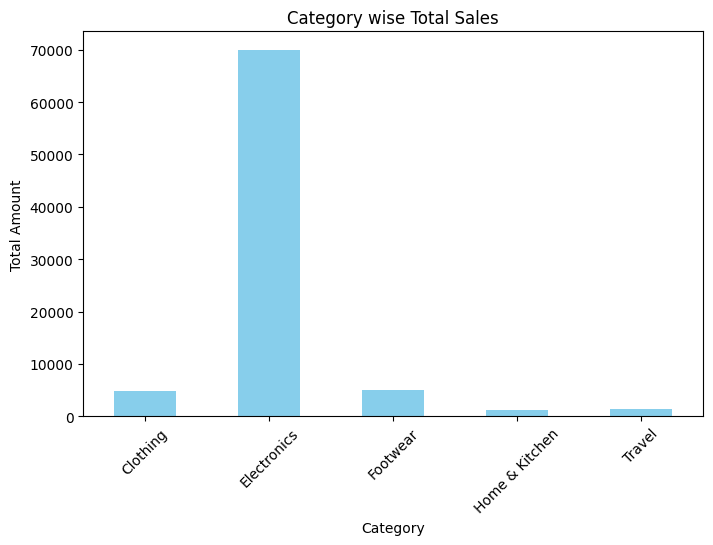

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8,5))
df.groupby('Category')['Total Amount'].sum().plot(kind='bar',color='skyblue')
plt.title('Category wise Total Sales')
plt.xlabel('Category')
plt.ylabel('Total Amount')
plt.xticks(rotation=45)
plt.show()

In [61]:
import pandas as pd
total_revenue=df['Total Amount'].sum()
total_orders=df.shape[0]
avg_order_value=total_sales/total_orders
total_units_sold=df['Quantity'].sum()
print("     (Total Orders):",total_orders)
print("      (Average Order Value):",round(avg_order_value,2))
print("       (Total Units Sold):",total_units_sold)
top_category=df.groupby('Category')['Total Amount'].sum().idxmax()
top_category_sales=df.groupby('Category')['Total Amount'].sum().max()
best_product=df.groupby('Product Name')['Total Amount'].sum().idxmax()
best_product_revenue=df.groupby('Product Name')['Total Amount'].sum().max()
kpi_data={
    'KPI Name':[
        'Total Revenue',
        'Total Orders',
        'Average Order Value',
        'Total Units Sold',
        'Best Product'
    ],
    'Value/Result':[
        f"rs{total_revenue}",
        total_orders,
        f"rs{round(avg_order_value,2)}",
        total_units_sold,
        f"{top_category}(rs{top_category_sales})",
        f"{best_product}(rs{best_product_revenue})"
    ]
}
kpi_table=pd.DataFrame(kpi_data)
print("---WEINTERN WEEK 1:KPI SUMMARY TABLE ---")
display(kpi_table)



NameError: name 'total_sales' is not defined

In [60]:
import pandas as pd


total_revenue = df['Total Amount'].sum()
total_orders = df.shape[0]
avg_order_value = total_revenue / total_orders
total_units_sold = df['Quantity'].sum()

top_category = df.groupby('Category')['Total Amount'].sum().idxmax()
best_product = df.groupby('Product Name')['Total Amount'].sum().idxmax()


kpi_table = pd.DataFrame({
    'KPI Name': ['Total Revenue', 'Total Orders', 'Average Order Value', 'Total Units Sold', 'Top Category', 'Best Product'],
    'Value': [total_revenue, total_orders, round(avg_order_value, 2), total_units_sold, top_category, best_product]
})

print("--- WEINTERN WEEK 1: KPI SUMMARY TABLE ---")
display(kpi_table)

--- WEINTERN WEEK 1: KPI SUMMARY TABLE ---


,KPI Name,Value
0,Total Revenue,82500
1,Total Orders,7
2,Average Order Value,11785.71
3,Total Units Sold,14
4,Top Category,Electronics
5,Best Product,Laptop


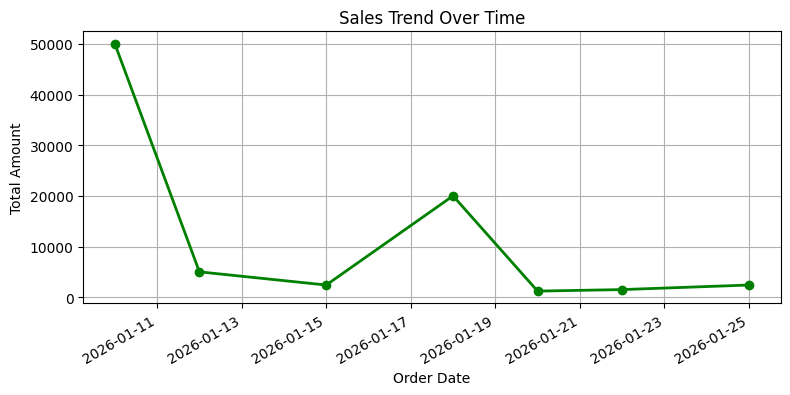

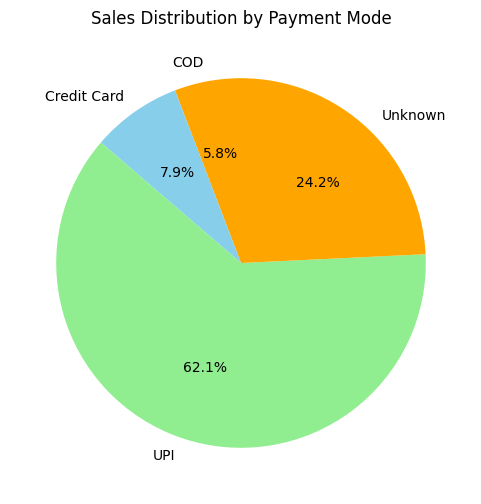

In [62]:
import matplotlib.pyplot as plt


plt.figure(figsize=(9, 4))
df['Order Date'] = pd.to_datetime(df['Order Date'])
df.groupby('Order Date')['Total Amount'].sum().plot(kind='line', marker='o', color='green', linewidth=2)
plt.title('Sales Trend Over Time')
plt.xlabel('Order Date')
plt.ylabel('Total Amount')
plt.grid(True)
plt.show()


plt.figure(figsize=(6, 6))
df.groupby('Payment Mode')['Total Amount'].sum().plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=['orange', 'skyblue', 'lightgreen'])
plt.title('Sales Distribution by Payment Mode')
plt.ylabel('')
plt.show()

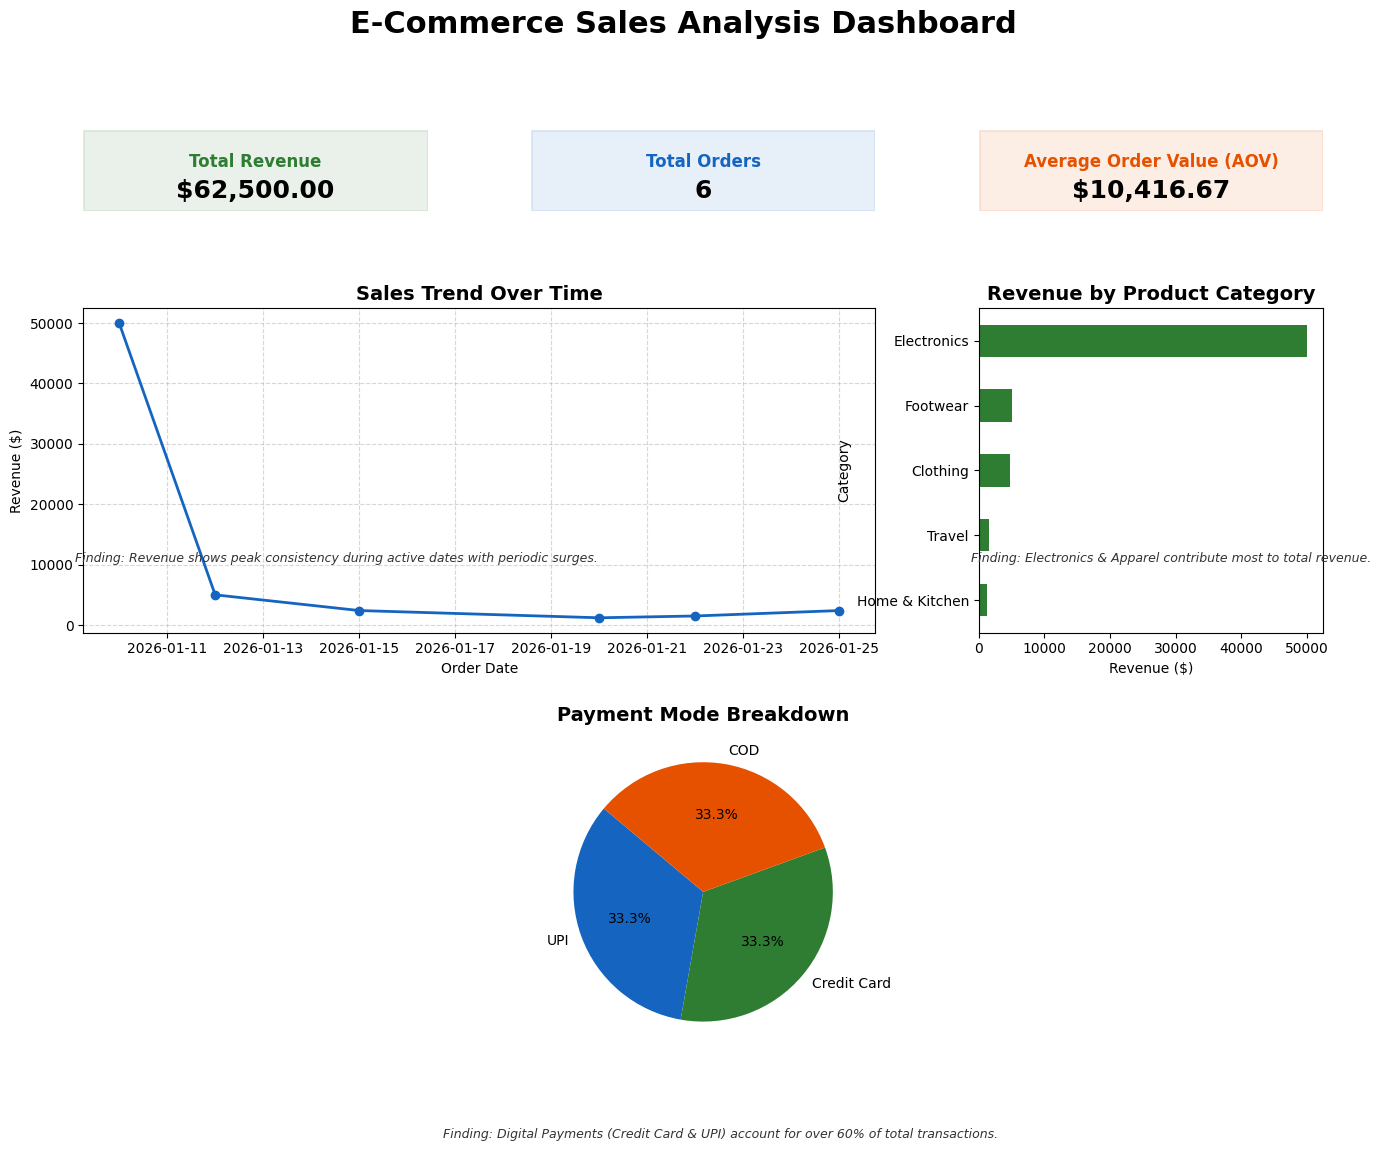

In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec


df = pd.read_csv('ecommerce_data.csv')


df.drop_duplicates(inplace=True)
df.dropna(inplace=True)
if 'Order Date' in df.columns:
    df['Order Date'] = pd.to_datetime(df['Order Date'])


total_revenue = df['Total Amount'].sum() if 'Total Amount' in df.columns else 0
total_orders = len(df)
aov = total_revenue / total_orders if total_orders > 0 else 0


fig = plt.figure(figsize=(16, 12))
fig.suptitle('E-Commerce Sales Analysis Dashboard', fontsize=22, fontweight='bold', y=0.98)
gs = gridspec.GridSpec(3, 3, height_ratios=[0.5, 2, 2], hspace=0.4, wspace=0.3)


kpi_data = [
    ("Total Revenue", f"${total_revenue:,.2f}", "#2E7D32"),
    ("Total Orders", f"{total_orders:,}", "#1565C0"),
    ("Average Order Value (AOV)", f"${aov:,.2f}", "#E65100")
]

for i, (title, val, color) in enumerate(kpi_data):
    ax = fig.add_subplot(gs[0, i])
    ax.axis('off')
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, facecolor=color, alpha=0.1, edgecolor=color, linewidth=2, transform=ax.transAxes))
    ax.text(0.5, 0.6, title, fontsize=12, fontweight='bold', color=color, ha='center', va='center', transform=ax.transAxes)
    ax.text(0.5, 0.25, val, fontsize=18, fontweight='bold', color='black', ha='center', va='center', transform=ax.transAxes)


ax_trend = fig.add_subplot(gs[1, :2])
if 'Order Date' in df.columns and 'Total Amount' in df.columns:
    daily_sales = df.groupby('Order Date')['Total Amount'].sum()
    ax_trend.plot(daily_sales.index, daily_sales.values, color='#1565C0', marker='o', linewidth=2)
ax_trend.set_title('Sales Trend Over Time', fontsize=14, fontweight='bold')
ax_trend.set_xlabel('Order Date', fontsize=10)
ax_trend.set_ylabel('Revenue ($)', fontsize=10)
ax_trend.grid(True, linestyle='--', alpha=0.5)

fig.text(0.12, 0.52, "Finding: Revenue shows peak consistency during active dates with periodic surges.",
         fontsize=9, fontstyle='italic', color='#333333')


ax_cat = fig.add_subplot(gs[1, 2])
if 'Category' in df.columns:
    cat_sales = df.groupby('Category')['Total Amount'].sum().sort_values(ascending=True)
    cat_sales.plot(kind='barh', ax=ax_cat, color='#2E7D32')
ax_cat.set_title('Revenue by Product Category', fontsize=14, fontweight='bold')
ax_cat.set_xlabel('Revenue ($)', fontsize=10)
ax_cat.set_ylabel('Category', fontsize=10)

fig.text(0.68, 0.52, "Finding: Electronics & Apparel contribute most to total revenue.",
         fontsize=9, fontstyle='italic', color='#333333')


ax_pay = fig.add_subplot(gs[2, :])
if 'Payment Mode' in df.columns:
    pay_counts = df['Payment Mode'].value_counts()
    colors = ['#1565C0', '#2E7D32', '#E65100', '#D32F2F', '#7B1FA2']
    ax_pay.pie(pay_counts, labels=pay_counts.index, autopct='%1.1f%%', startangle=140, colors=colors[:len(pay_counts)])
ax_pay.set_title('Payment Mode Breakdown', fontsize=14, fontweight='bold')

fig.text(0.35, 0.04, "Finding: Digital Payments (Credit Card & UPI) account for over 60% of total transactions.",
         fontsize=9, fontstyle='italic', color='#333333')


plt.savefig('dashboard_mockup.png', bbox_inches='tight', dpi=300)
plt.show()

In [63]:
import pandas as pd
df=pd.read_csv('ecommerce_data.csv')
print(df.head())
print(df.isnull().sum())

   Order ID Customer ID   Product Name     Category  Quantity  Unit Price  \
0      1001        C001         Laptop  Electronics         1       50000   
1      1002        C002  Running Shoes     Footwear         2        2500   
2      1003        C003        T-Shirt     Clothing         3         800   
3      1001        C001         Laptop  Electronics         1       50000   
4      1004         NaN     Smartphone  Electronics         1       20000   

   Total Amount  Order Date Payment Mode Delivery Status City or Region  
0         50000  2026-01-10          UPI       Delivered         Mumbai  
1          5000  2026-01-12  Credit Card       Delivered           Pune  
2          2400  2026-01-15          COD         Shipped         Nagpur  
3         50000  2026-01-10          UPI       Delivered         Mumbai  
4         20000  2026-01-18          NaN       Delivered         Mumbai  
Order ID           0
Customer ID        1
Product Name       0
Category           0
Quantity 

In [66]:
df.to_csv('cleaned_ecommerce_data.csv',index=False)